# **Análisis resultados LLM**

En este notebook, analizaremos los datos obtenidos por el LLM que ha evaluado la calidad de las imágenes de explicabilidad.

In [9]:
import os
from huggingface_hub import HfApi
from huggingface_hub import list_bucket_tree
from huggingface_hub import download_bucket_files
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from huggingface_hub import batch_bucket_files
import io
from pathlib import Path


In [ ]:
os.environ["HF_TOKEN"] = "mi_token"

bucket_id = "z72pepee/tfm-explicabilidad"

token = os.environ.get("HF_TOKEN")
if not token:
    raise EnvironmentError("Define HF_TOKEN en el entorno antes de ejecutar esta celda")

api = HfApi(token=token)

In [11]:
carpeta_objetivo = "LLM_dataset3_googleViT/"


# Obtenemos la lista exacta de archivos dentro de esa carpeta
archivos_remotos = [
    item.path
    for item in list_bucket_tree(bucket_id, prefix=carpeta_objetivo)
    if item.type == "file"
]
#print(archivos_remotos[0])
# Construimos la lista de tuplas que necesita download_bucket_files
# Formato: (ruta_en_el_bucket, ruta_en_tu_disco_local)
# Al poner (ruta, ruta) se guardarán conservando la misma estructura de carpetas.
archivos_a_descargar = [
    (ruta, ruta)
    for ruta in archivos_remotos
]

print(f"¡Se han encontrado {len(archivos_a_descargar)} archivos para descargar!")

# Descargamos los archivos en bloque
if archivos_a_descargar:
    download_bucket_files(
        bucket_id,
        files=archivos_a_descargar
    )
    print("¡Descarga completada con éxito!")
else:
    print("No se encontró nada para descargar (la carpeta no existe o está vacía).")

¡Se han encontrado 99 archivos para descargar!


¡Descarga completada con éxito!


In [12]:
def procesar_modelo(ruta_modelo):
    nombre_modelo = os.path.basename(os.path.normpath(ruta_modelo))
    print(f"[INFO] Iniciando procesamiento del modelo: {nombre_modelo}...")
    lista_dataframes = []

    if not os.path.exists(ruta_modelo):
        print(f"[ERROR] No se encuentra la ruta: {ruta_modelo}")
        return

    # ==========================================
    # CREACIÓN DE DIRECTORIOS DE SALIDA
    # ==========================================
    carpeta_base_salida = "Analisis_resultados_LLM"
    ruta_salida = os.path.join(carpeta_base_salida, nombre_modelo)
    os.makedirs(ruta_salida, exist_ok=True)
    print(f"[INFO] Los resultados se guardarán en: {ruta_salida}")

    # Lectura y consolidación de datos
    for tecnica in os.listdir(ruta_modelo):
        ruta_tecnica = os.path.join(ruta_modelo, tecnica)

        if os.path.isdir(ruta_tecnica):
            archivos_csv = [f for f in os.listdir(ruta_tecnica) if f.endswith('.csv')]
            for archivo in archivos_csv:
                ruta_csv = os.path.join(ruta_tecnica, archivo)
                try:
                    df_parcial = pd.read_csv(ruta_csv)
                    df_parcial['Tecnica'] = tecnica
                    df_parcial['Modelo'] = nombre_modelo
                    lista_dataframes.append(df_parcial)
                except Exception as e:
                    print(f"[AVISO] Error leyendo {ruta_csv}: {e}")

    if not lista_dataframes:
        print("[ERROR] No se encontraron datos CSV en las subcarpetas.")
        return

    df_consolidado = pd.concat(lista_dataframes, ignore_index=True)
    df_consolidado['puntuacion'] = pd.to_numeric(df_consolidado['puntuacion'], errors='coerce')
    df_consolidado['tiempo_segundos'] = pd.to_numeric(df_consolidado['tiempo_segundos'], errors='coerce')

    # Exportar CSV Tabular a la ruta
    ruta_tabular = os.path.join(ruta_salida, f"{nombre_modelo}_Datos_Tabulares.csv")
    df_consolidado.to_csv(ruta_tabular, index=False)
    print(f"[OK] Guardado CSV completo: {ruta_tabular}")

    # Cálculo de Métricas por Técnica
    df_metricas = df_consolidado.groupby('Tecnica').agg(
        Total_Imagenes=('imagen', 'count'),
        Fallos_None=('puntuacion', lambda x: x.isna().sum()),
        Puntuacion_Media=('puntuacion', 'mean'),
        Puntuacion_Desv_Tipica=('puntuacion', 'std'),
        Puntuacion_Mediana=('puntuacion', 'median'),
        Puntuacion_Minima=('puntuacion', 'min'),
        Puntuacion_Maxima=('puntuacion', 'max'),
        Tiempo_Total=('tiempo_segundos', 'sum'),
        Tiempo_Medio=('tiempo_segundos', 'mean'),
        Tiempo_Mediano=('tiempo_segundos', 'median'),
        Tiempo_Maximo=('tiempo_segundos', 'max')
    ).reset_index()

    df_metricas['Porcentaje_Fallos'] = (df_metricas['Fallos_None'] / df_metricas['Total_Imagenes']) * 100
    df_metricas.insert(0, 'Modelo', nombre_modelo)

    # Cálculo de Métricas Globales
    total_img_global = len(df_consolidado)
    fallos_global = df_consolidado['puntuacion'].isna().sum()
    porcentaje_fallos_global = (fallos_global / total_img_global) * 100
    tiempo_total_global = df_consolidado['tiempo_segundos'].sum()

    df_global = pd.DataFrame([{
        'Modelo': nombre_modelo,
        'Tecnica': 'GLOBAL',
        'Total_Imagenes': total_img_global,
        'Fallos_None': fallos_global,
        'Puntuacion_Media': df_consolidado['puntuacion'].mean(),
        'Puntuacion_Desv_Tipica': df_consolidado['puntuacion'].std(),
        'Puntuacion_Mediana': df_consolidado['puntuacion'].median(),
        'Puntuacion_Minima': df_consolidado['puntuacion'].min(),
        'Puntuacion_Maxima': df_consolidado['puntuacion'].max(),
        'Tiempo_Total': tiempo_total_global,
        'Tiempo_Medio': df_consolidado['tiempo_segundos'].mean(),
        'Tiempo_Mediano': df_consolidado['tiempo_segundos'].median(),
        'Tiempo_Maximo': df_consolidado['tiempo_segundos'].max(),
        'Porcentaje_Fallos': porcentaje_fallos_global
    }])

    df_metricas = pd.concat([df_metricas, df_global], ignore_index=True)

    # Exportar CSV de Métricas a la  ruta
    ruta_metricas = os.path.join(ruta_salida, f"{nombre_modelo}_Metricas_Estadisticas.csv")
    df_metricas.to_csv(ruta_metricas, index=False)
    print(f"[OK] Guardado CSV de Métricas: {ruta_metricas}")

    # Ranking de Imágenes con Errores
    df_fallos = df_consolidado[df_consolidado['puntuacion'].isna()]
    df_ranking = pd.DataFrame()

    if not df_fallos.empty:
        df_ranking = df_fallos.groupby('imagen').size().reset_index(name='Cantidad_Fallos')
        df_ranking = df_ranking.sort_values(by='Cantidad_Fallos', ascending=False)

        # Exportar CSV de Ranking a la nueva ruta
        ruta_ranking = os.path.join(ruta_salida, f"{nombre_modelo}_Ranking_Fallos_Imagenes.csv")
        df_ranking.to_csv(ruta_ranking, index=False)
        print(f"[OK] Guardado CSV de Ranking de Fallos: {ruta_ranking}")
    else:
        print("[INFO] No se registraron fallos. Se omite el archivo de ranking.")

    # ==========================================
    # IMPRESIÓN DEL ANÁLISIS
    # ==========================================
    print("\n" + "=" * 70)
    print(f"RESUMEN GLOBAL DEL MODELO: {nombre_modelo}")
    print("=" * 70)
    print(f" - Total de imágenes evaluadas: {total_img_global}")
    print(f" - Fallos totales (None):       {fallos_global} ({porcentaje_fallos_global:.2f}%)")
    print(f" - Puntuación Global:           Media {df_consolidado['puntuacion'].mean():.3f} | Mediana {df_consolidado['puntuacion'].median():.3f}")

    if tiempo_total_global > 3600:
        horas = tiempo_total_global // 3600
        minutos = (tiempo_total_global % 3600) // 60
        print(f" - Tiempo Total Computacional:  {tiempo_total_global:.1f} segundos ({int(horas)}h {int(minutos)}m)")
    elif tiempo_total_global > 60:
        minutos = tiempo_total_global // 60
        segundos = tiempo_total_global % 60
        print(f" - Tiempo Total Computacional:  {tiempo_total_global:.1f} segundos ({int(minutos)}m {int(segundos)}s)")
    else:
        print(f" - Tiempo Total Computacional:  {tiempo_total_global:.1f} segundos")

    print("\n" + "-" * 70)
    print("TOP 7: IMÁGENES CON MAYOR TASA DE ERROR")
    print("-" * 70)
    if not df_ranking.empty:
        for i, row in df_ranking.head(7).iterrows():
            print(f" - {row['imagen']}: {row['Cantidad_Fallos']} fallos")
    else:
        print(" - No se detectaron errores en la evaluación de imágenes.")

    print("\n" + "-" * 70)
    print("DESGLOSE POR TÉCNICA")
    print("-" * 70)

    for index, row in df_metricas.iloc[:-1].iterrows():
        print(f"\nTécnica: {row['Tecnica']}")
        print(f"  * Procesado: {row['Total_Imagenes']} imágenes")
        print(f"  * Errores:   {row['Fallos_None']} ({row['Porcentaje_Fallos']:.2f}%)")

        if row['Total_Imagenes'] > row['Fallos_None']:
            print(f"  * Puntuación: Media {row['Puntuacion_Media']:.3f} | Mediana {row['Puntuacion_Mediana']:.3f} | Rango [{row['Puntuacion_Minima']:.2f} - {row['Puntuacion_Maxima']:.2f}]")
            print(f"  * Tiempo (s): Total {row['Tiempo_Total']:.1f}s | Medio {row['Tiempo_Medio']:.2f}s | Máx {row['Tiempo_Maximo']:.2f}s")
        else:
            print("  * [AVISO] Ausencia de puntuaciones válidas.")

    print("\n" + "=" * 70 + "\n")

    # ==========================================
    # VISUALIZACIONES
    # ==========================================
    print("[INFO] Generando gráficos estadísticos...")
    sns.set_theme(style="whitegrid")

    plt.figure(figsize=(10, 6))
    sns.boxplot(data=df_consolidado, x='Tecnica', y='puntuacion', hue='Tecnica', palette='viridis', legend=False)
    plt.title(f'Distribución de Puntuaciones - {nombre_modelo}', fontsize=14, fontweight='bold')
    plt.ylabel('Puntuación')
    plt.xlabel('Técnica')
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.savefig(os.path.join(ruta_salida, f"{nombre_modelo}_Boxplot.png"))
    plt.show()

    plt.figure(figsize=(10, 6))
    sns.scatterplot(data=df_consolidado, x='tiempo_segundos', y='puntuacion', hue='Tecnica', palette='Set2', s=100, alpha=0.7)
    plt.title(f'Relación Tiempo vs Puntuación - {nombre_modelo}', fontsize=14, fontweight='bold')
    plt.ylabel('Puntuación')
    plt.xlabel('Tiempo de ejecución (s)')
    plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
    plt.tight_layout()
    plt.savefig(os.path.join(ruta_salida, f"{nombre_modelo}_Dispersion.png"))
    plt.show()

    plt.figure(figsize=(10, 6))
    df_grafico_metricas = df_metricas[df_metricas['Tecnica'] != 'GLOBAL']
    sns.barplot(data=df_grafico_metricas, x='Tecnica', y='Porcentaje_Fallos', color='#8e44ad')
    plt.title(f'Tasa de Error por Técnica - {nombre_modelo}', fontsize=14, fontweight='bold')
    plt.ylabel('Tasa de Error (%)')
    plt.xlabel('Técnica')
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.savefig(os.path.join(ruta_salida, f"{nombre_modelo}_Errores.png"))
    plt.show()

    print("[INFO] Proceso finalizado correctamente.")



[INFO] Iniciando procesamiento del modelo: Qwen3.5-27B-GGUF...
[INFO] Los resultados se guardarán en: Analisis_resultados_LLM/Qwen3.5-27B-GGUF
[OK] Guardado CSV completo: Analisis_resultados_LLM/Qwen3.5-27B-GGUF/Qwen3.5-27B-GGUF_Datos_Tabulares.csv
[OK] Guardado CSV de Métricas: Analisis_resultados_LLM/Qwen3.5-27B-GGUF/Qwen3.5-27B-GGUF_Metricas_Estadisticas.csv
[OK] Guardado CSV de Ranking de Fallos: Analisis_resultados_LLM/Qwen3.5-27B-GGUF/Qwen3.5-27B-GGUF_Ranking_Fallos_Imagenes.csv

RESUMEN GLOBAL DEL MODELO: Qwen3.5-27B-GGUF
 - Total de imágenes evaluadas: 220
 - Fallos totales (None):       12 (5.45%)
 - Puntuación Global:           Media 2.351 | Mediana 2.000
 - Tiempo Total Computacional:  26992.2 segundos (7h 29m)

----------------------------------------------------------------------
TOP 7: IMÁGENES CON MAYOR TASA DE ERROR
----------------------------------------------------------------------
 - 4ed4fca6-0e1c-4e7c-804a-50c42f6427bb.png: 2 fallos
 - 5d2b495b-2947-48f2-a708-b812

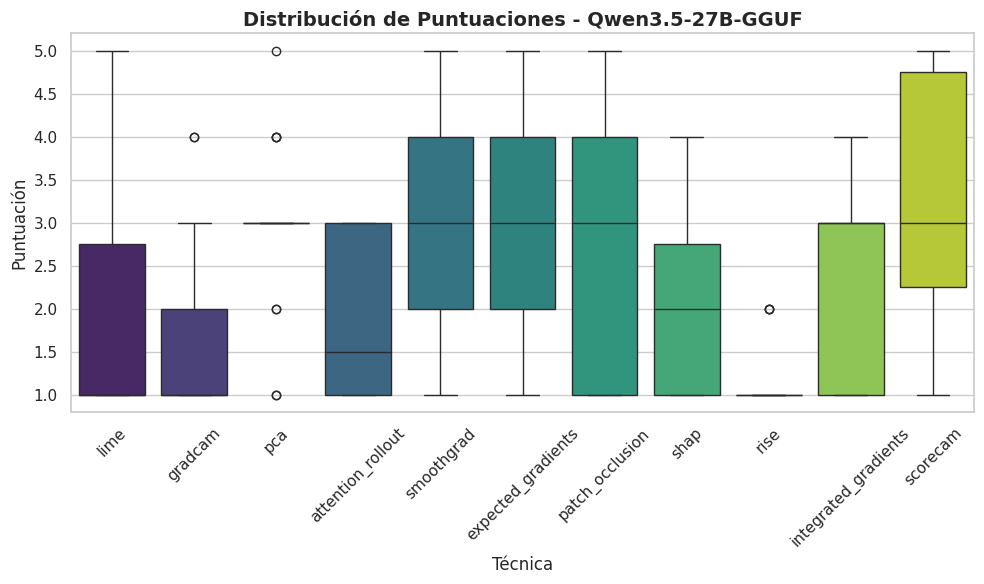

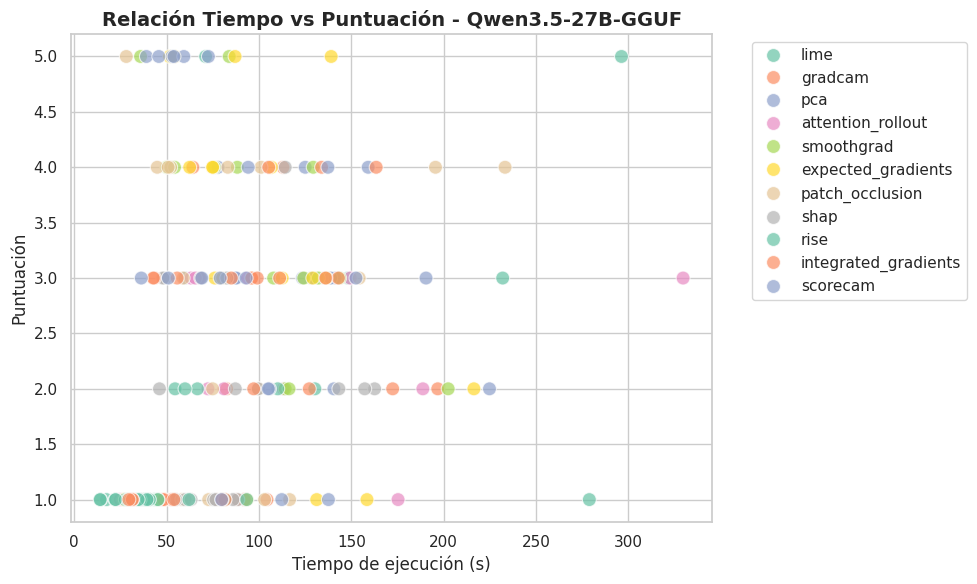

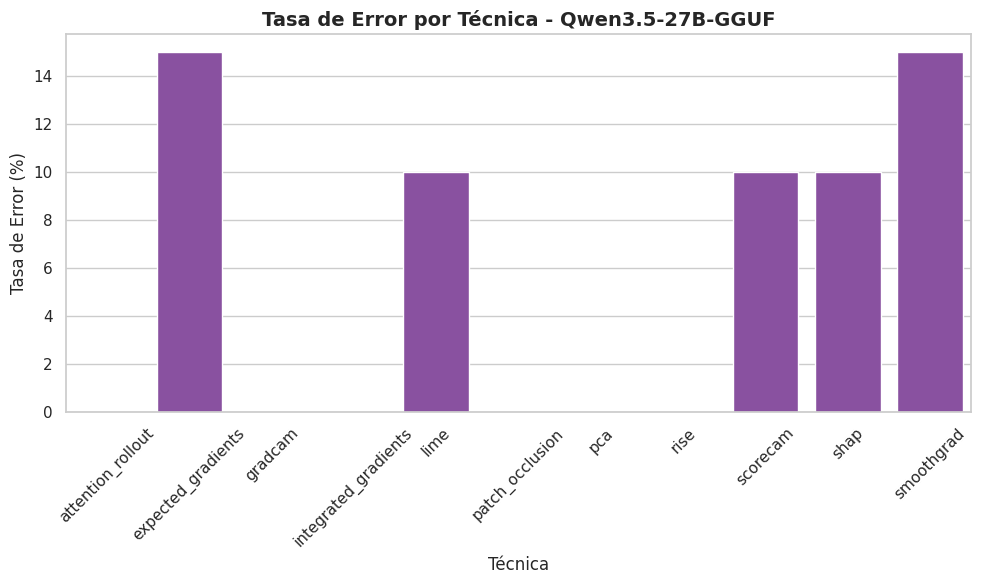

[INFO] Proceso finalizado correctamente.
[INFO] Iniciando procesamiento del modelo: gemma-4-E2B-it-GGUF...
[INFO] Los resultados se guardarán en: Analisis_resultados_LLM/gemma-4-E2B-it-GGUF
[OK] Guardado CSV completo: Analisis_resultados_LLM/gemma-4-E2B-it-GGUF/gemma-4-E2B-it-GGUF_Datos_Tabulares.csv
[OK] Guardado CSV de Métricas: Analisis_resultados_LLM/gemma-4-E2B-it-GGUF/gemma-4-E2B-it-GGUF_Metricas_Estadisticas.csv
[INFO] No se registraron fallos. Se omite el archivo de ranking.

RESUMEN GLOBAL DEL MODELO: gemma-4-E2B-it-GGUF
 - Total de imágenes evaluadas: 220
 - Fallos totales (None):       0 (0.00%)
 - Puntuación Global:           Media 4.327 | Mediana 5.000
 - Tiempo Total Computacional:  2185.6 segundos (36m 25s)

----------------------------------------------------------------------
TOP 7: IMÁGENES CON MAYOR TASA DE ERROR
----------------------------------------------------------------------
 - No se detectaron errores en la evaluación de imágenes.

--------------------------

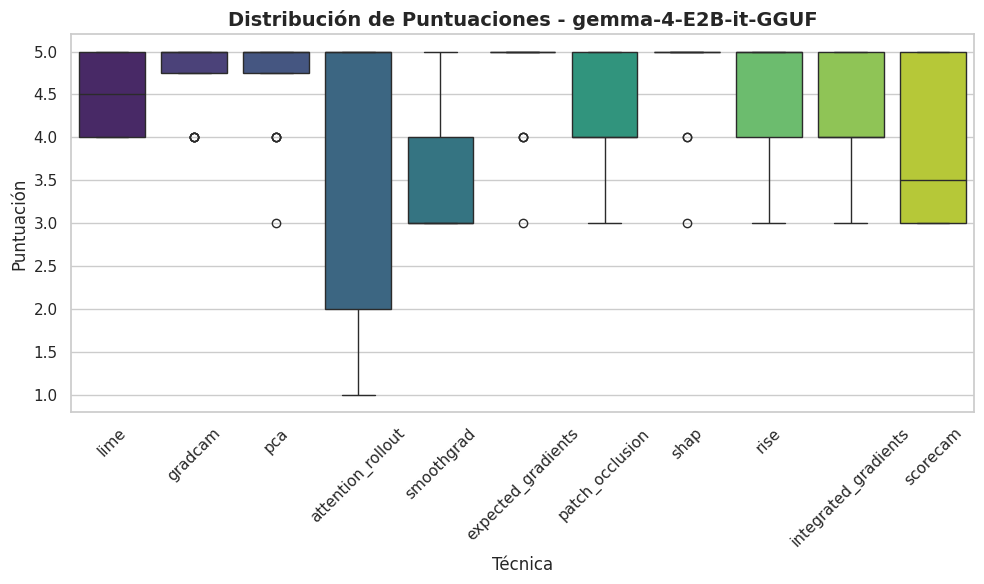

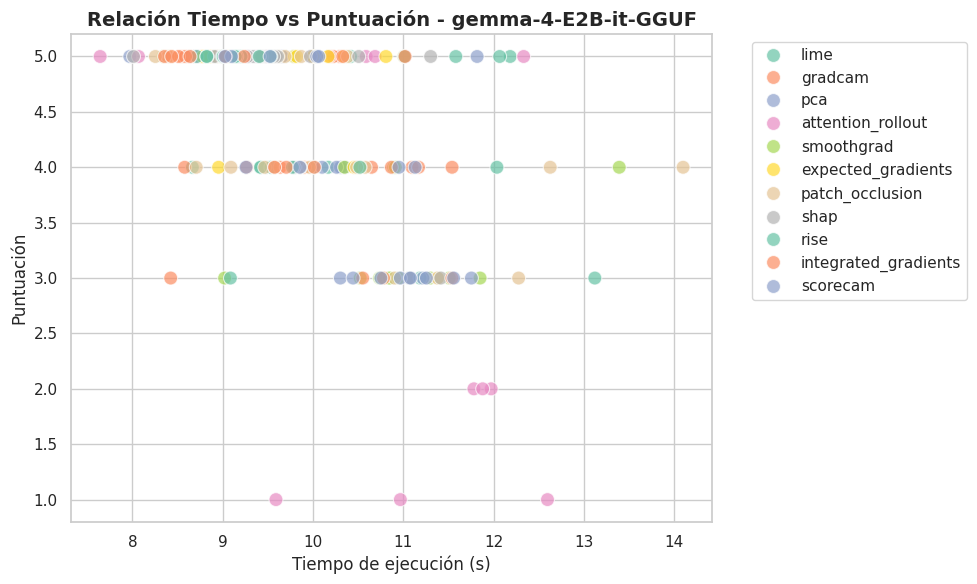

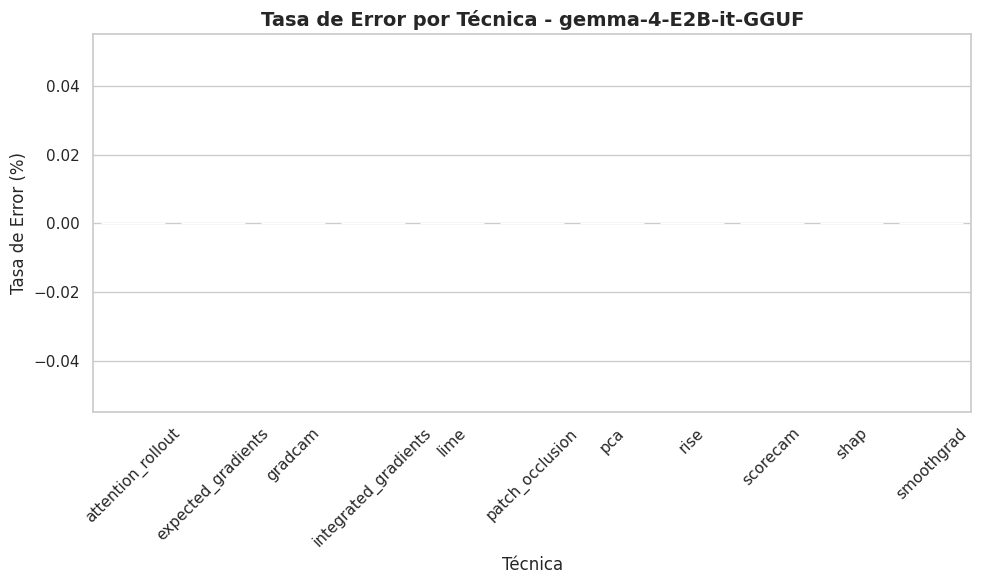

[INFO] Proceso finalizado correctamente.
[INFO] Iniciando procesamiento del modelo: Qwen3.8-27B-GGUF...
[INFO] Los resultados se guardarán en: Analisis_resultados_LLM/Qwen3.8-27B-GGUF
[OK] Guardado CSV completo: Analisis_resultados_LLM/Qwen3.8-27B-GGUF/Qwen3.8-27B-GGUF_Datos_Tabulares.csv
[OK] Guardado CSV de Métricas: Analisis_resultados_LLM/Qwen3.8-27B-GGUF/Qwen3.8-27B-GGUF_Metricas_Estadisticas.csv
[INFO] No se registraron fallos. Se omite el archivo de ranking.

RESUMEN GLOBAL DEL MODELO: Qwen3.8-27B-GGUF
 - Total de imágenes evaluadas: 220
 - Fallos totales (None):       0 (0.00%)
 - Puntuación Global:           Media 2.150 | Mediana 2.000
 - Tiempo Total Computacional:  22819.1 segundos (6h 20m)

----------------------------------------------------------------------
TOP 7: IMÁGENES CON MAYOR TASA DE ERROR
----------------------------------------------------------------------
 - No se detectaron errores en la evaluación de imágenes.

-----------------------------------------------

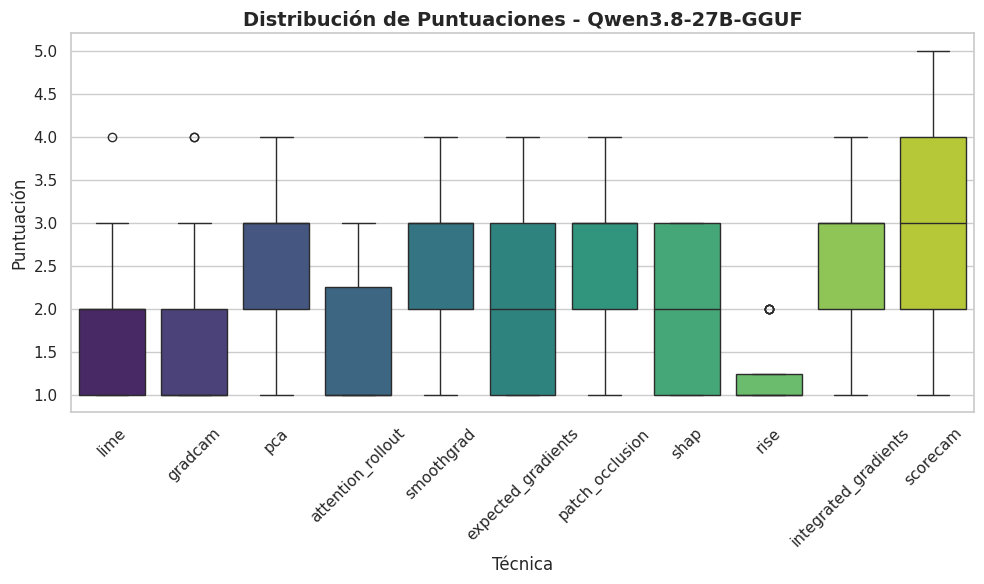

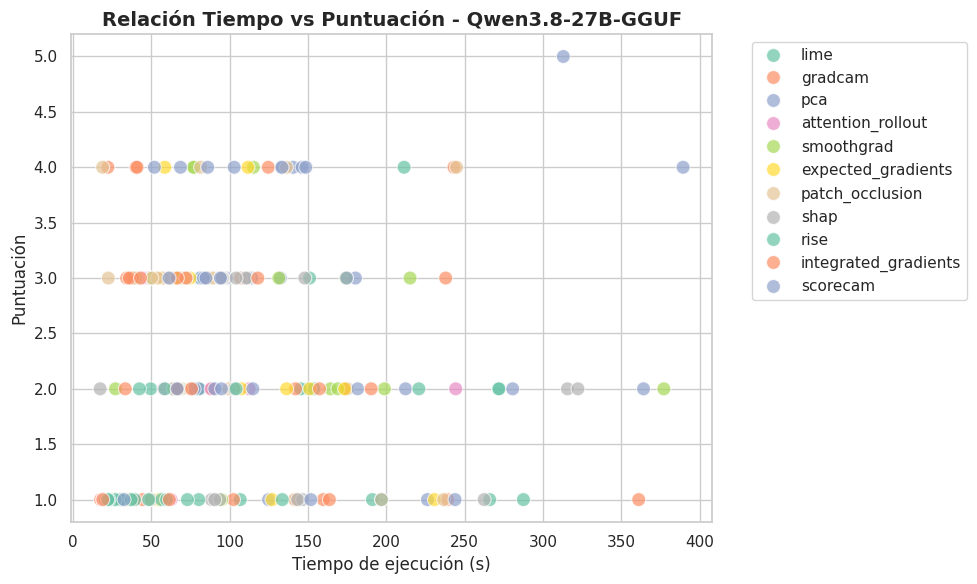

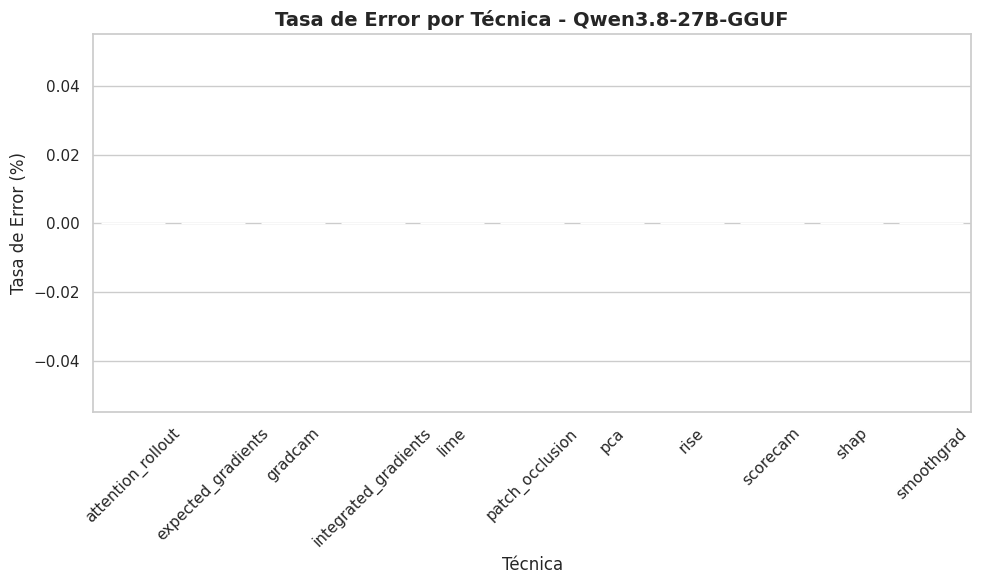

[INFO] Proceso finalizado correctamente.
[INFO] Iniciando procesamiento del modelo: Qwen3.5-2B-GGUF...
[INFO] Los resultados se guardarán en: Analisis_resultados_LLM/Qwen3.5-2B-GGUF
[OK] Guardado CSV completo: Analisis_resultados_LLM/Qwen3.5-2B-GGUF/Qwen3.5-2B-GGUF_Datos_Tabulares.csv
[OK] Guardado CSV de Métricas: Analisis_resultados_LLM/Qwen3.5-2B-GGUF/Qwen3.5-2B-GGUF_Metricas_Estadisticas.csv
[OK] Guardado CSV de Ranking de Fallos: Analisis_resultados_LLM/Qwen3.5-2B-GGUF/Qwen3.5-2B-GGUF_Ranking_Fallos_Imagenes.csv

RESUMEN GLOBAL DEL MODELO: Qwen3.5-2B-GGUF
 - Total de imágenes evaluadas: 220
 - Fallos totales (None):       138 (62.73%)
 - Puntuación Global:           Media 3.305 | Mediana 4.000
 - Tiempo Total Computacional:  58926.3 segundos (16h 22m)

----------------------------------------------------------------------
TOP 7: IMÁGENES CON MAYOR TASA DE ERROR
----------------------------------------------------------------------
 - 22ec3d57-1317-4253-8596-e9123ecadcae.png: 9 fal

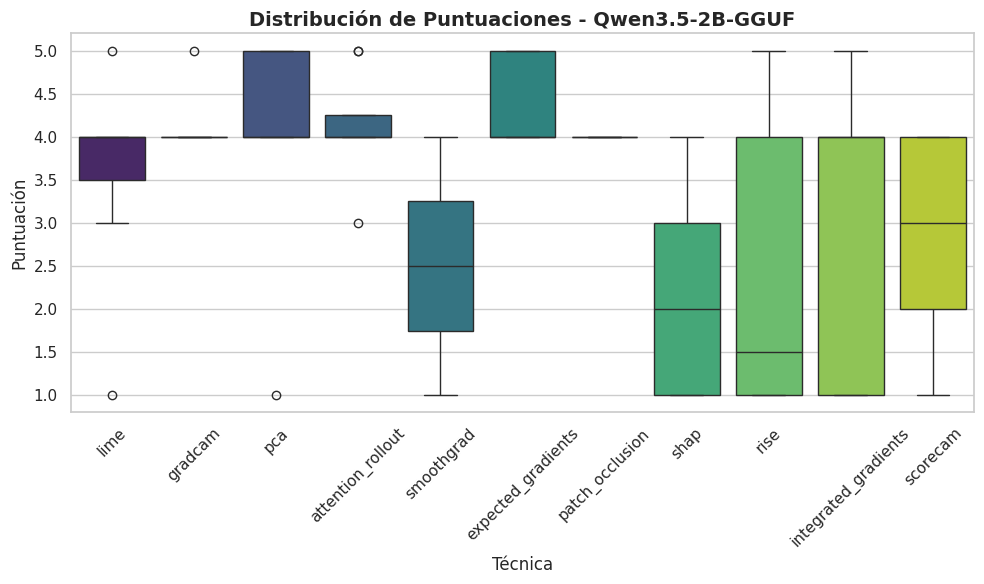

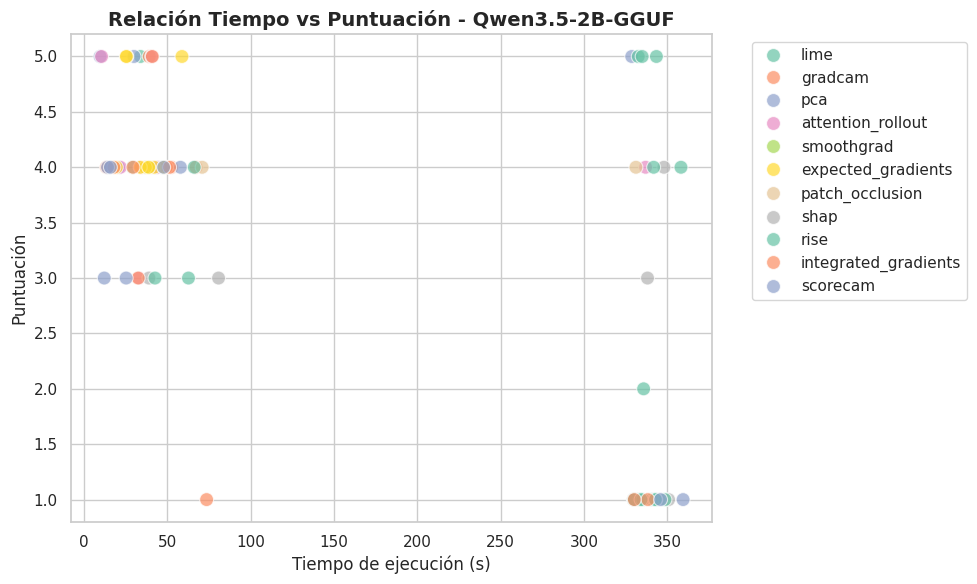

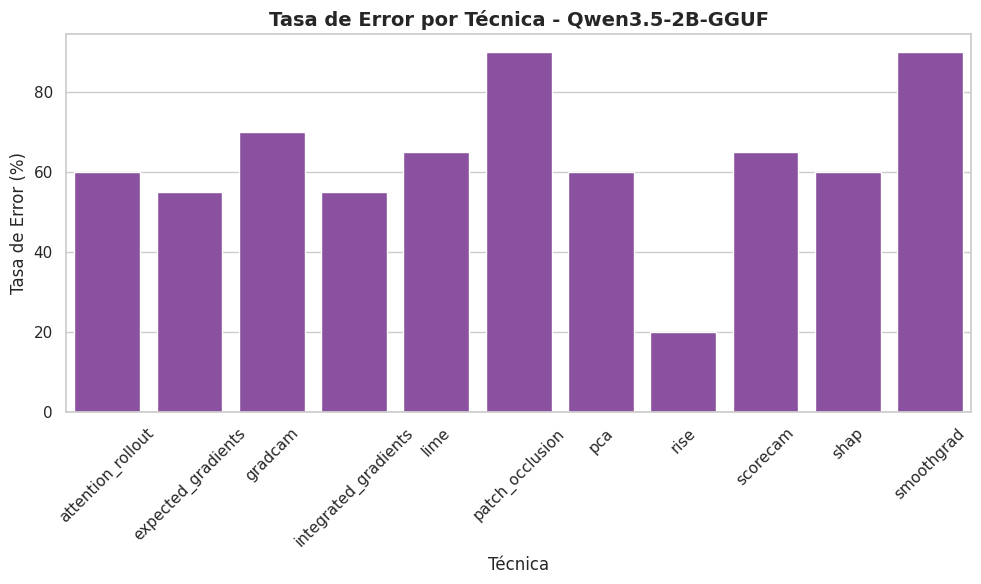

[INFO] Proceso finalizado correctamente.
[INFO] Iniciando procesamiento del modelo: Qwen3.5-4B-GGUF...
[INFO] Los resultados se guardarán en: Analisis_resultados_LLM/Qwen3.5-4B-GGUF
[OK] Guardado CSV completo: Analisis_resultados_LLM/Qwen3.5-4B-GGUF/Qwen3.5-4B-GGUF_Datos_Tabulares.csv
[OK] Guardado CSV de Métricas: Analisis_resultados_LLM/Qwen3.5-4B-GGUF/Qwen3.5-4B-GGUF_Metricas_Estadisticas.csv
[OK] Guardado CSV de Ranking de Fallos: Analisis_resultados_LLM/Qwen3.5-4B-GGUF/Qwen3.5-4B-GGUF_Ranking_Fallos_Imagenes.csv

RESUMEN GLOBAL DEL MODELO: Qwen3.5-4B-GGUF
 - Total de imágenes evaluadas: 220
 - Fallos totales (None):       17 (7.73%)
 - Puntuación Global:           Media 3.340 | Mediana 4.000
 - Tiempo Total Computacional:  52561.5 segundos (14h 36m)

----------------------------------------------------------------------
TOP 7: IMÁGENES CON MAYOR TASA DE ERROR
----------------------------------------------------------------------
 - 06d1610f-aa93-4a71-af7e-d6b0e1760e45.png: 2 fallo

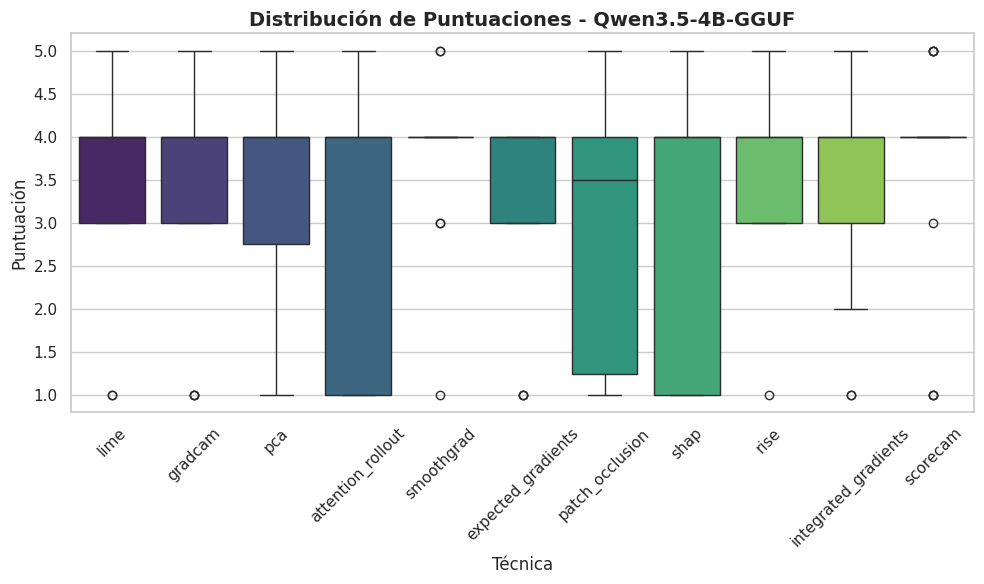

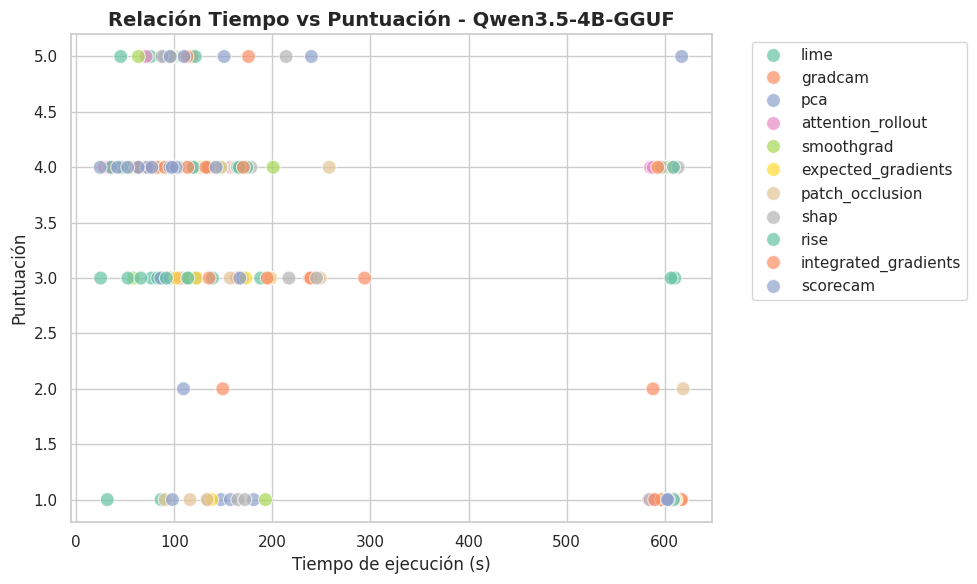

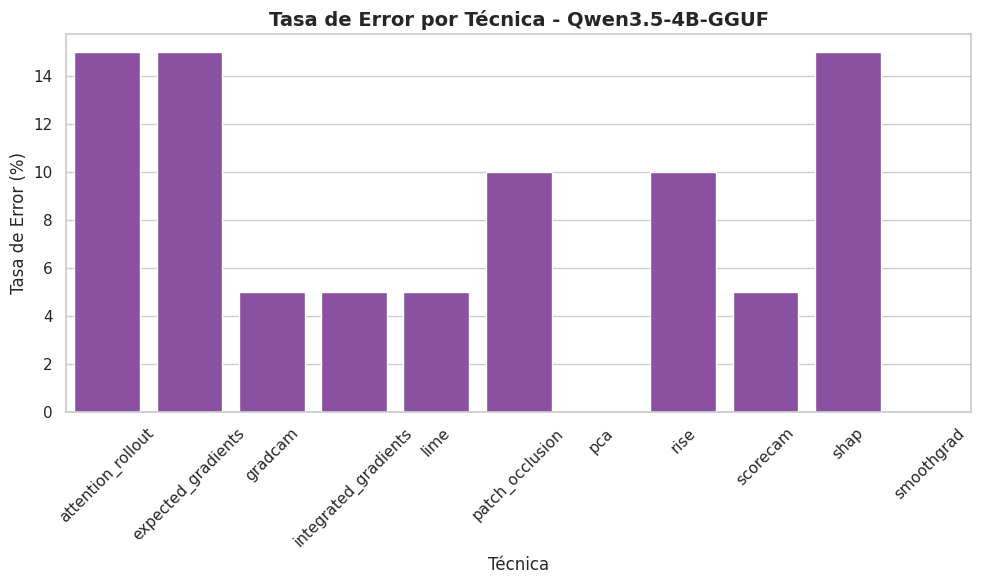

[INFO] Proceso finalizado correctamente.
[INFO] Iniciando procesamiento del modelo: gemma-4-E4B-it-GGUF...
[INFO] Los resultados se guardarán en: Analisis_resultados_LLM/gemma-4-E4B-it-GGUF
[OK] Guardado CSV completo: Analisis_resultados_LLM/gemma-4-E4B-it-GGUF/gemma-4-E4B-it-GGUF_Datos_Tabulares.csv
[OK] Guardado CSV de Métricas: Analisis_resultados_LLM/gemma-4-E4B-it-GGUF/gemma-4-E4B-it-GGUF_Metricas_Estadisticas.csv
[INFO] No se registraron fallos. Se omite el archivo de ranking.

RESUMEN GLOBAL DEL MODELO: gemma-4-E4B-it-GGUF
 - Total de imágenes evaluadas: 220
 - Fallos totales (None):       0 (0.00%)
 - Puntuación Global:           Media 4.386 | Mediana 5.000
 - Tiempo Total Computacional:  3220.3 segundos (53m 40s)

----------------------------------------------------------------------
TOP 7: IMÁGENES CON MAYOR TASA DE ERROR
----------------------------------------------------------------------
 - No se detectaron errores en la evaluación de imágenes.

--------------------------

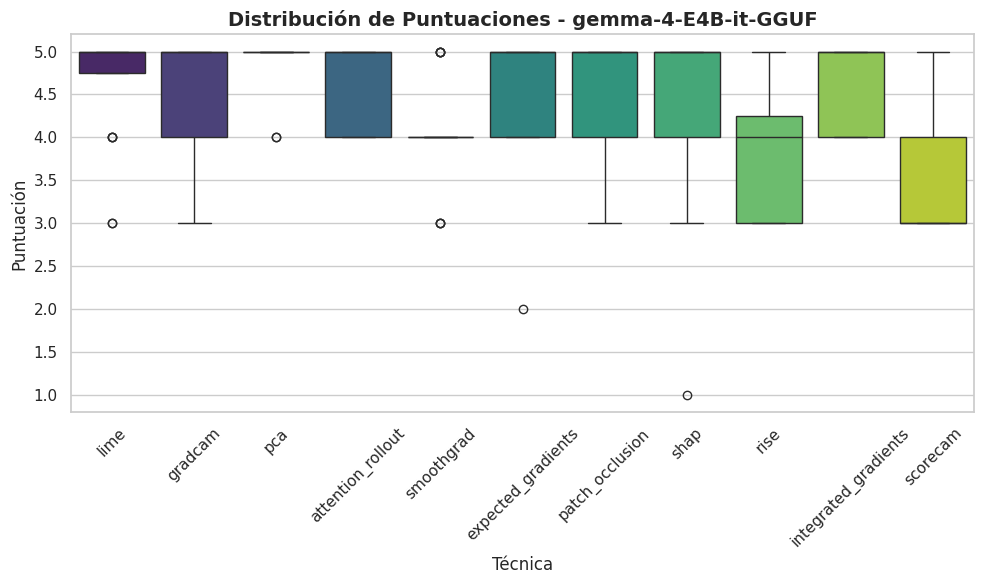

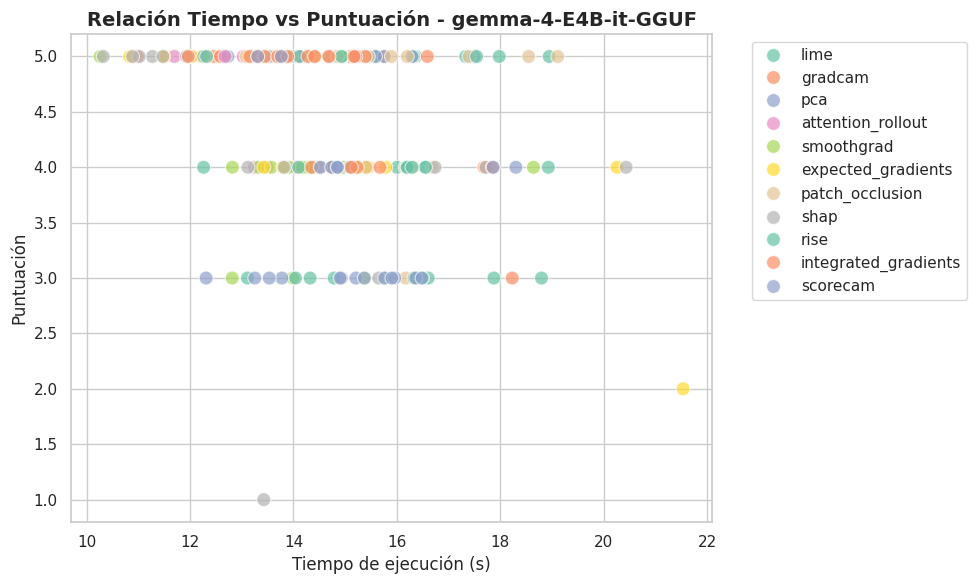

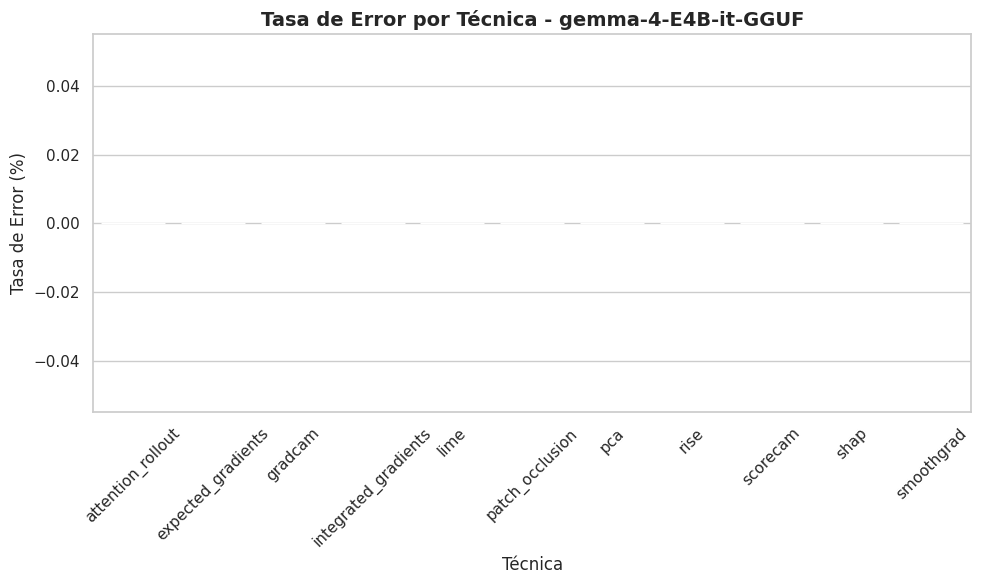

[INFO] Proceso finalizado correctamente.
[INFO] Iniciando procesamiento del modelo: gemma-4-12b-it-GGUF...
[INFO] Los resultados se guardarán en: Analisis_resultados_LLM/gemma-4-12b-it-GGUF
[OK] Guardado CSV completo: Analisis_resultados_LLM/gemma-4-12b-it-GGUF/gemma-4-12b-it-GGUF_Datos_Tabulares.csv
[OK] Guardado CSV de Métricas: Analisis_resultados_LLM/gemma-4-12b-it-GGUF/gemma-4-12b-it-GGUF_Metricas_Estadisticas.csv
[OK] Guardado CSV de Ranking de Fallos: Analisis_resultados_LLM/gemma-4-12b-it-GGUF/gemma-4-12b-it-GGUF_Ranking_Fallos_Imagenes.csv

RESUMEN GLOBAL DEL MODELO: gemma-4-12b-it-GGUF
 - Total de imágenes evaluadas: 220
 - Fallos totales (None):       14 (6.36%)
 - Puntuación Global:           Media 4.704 | Mediana 5.000
 - Tiempo Total Computacional:  17411.3 segundos (4h 50m)

----------------------------------------------------------------------
TOP 7: IMÁGENES CON MAYOR TASA DE ERROR
----------------------------------------------------------------------
 - 5d2b495b-2947-

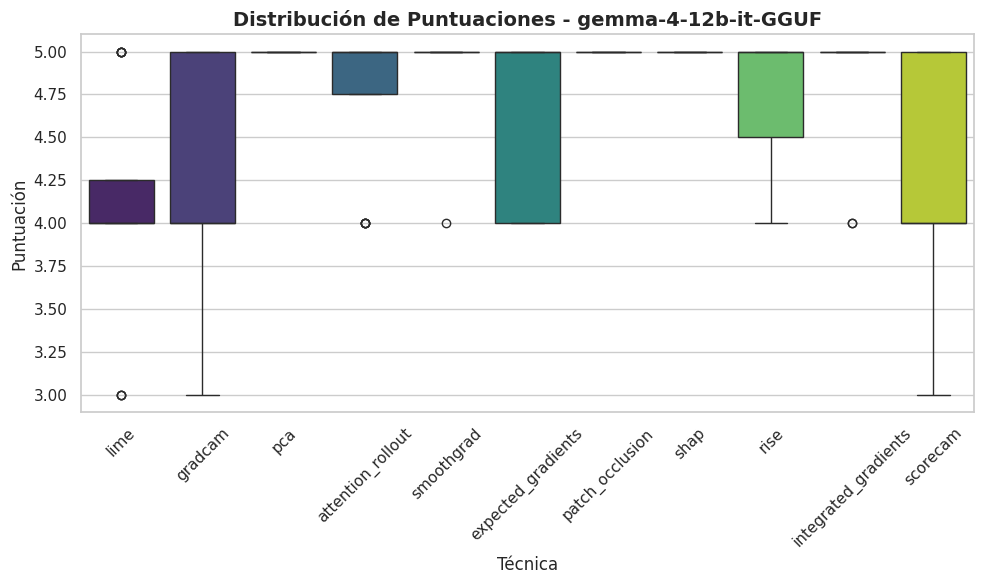

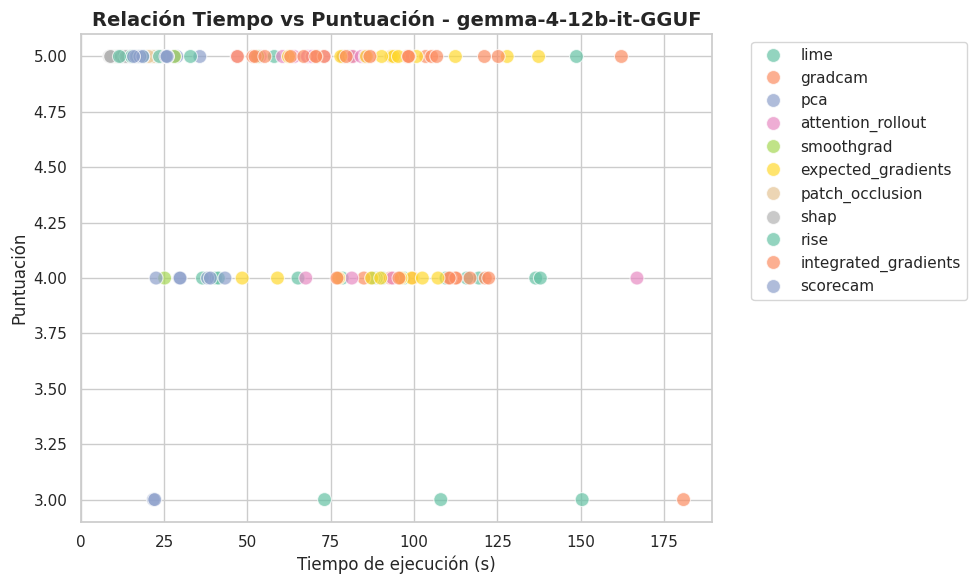

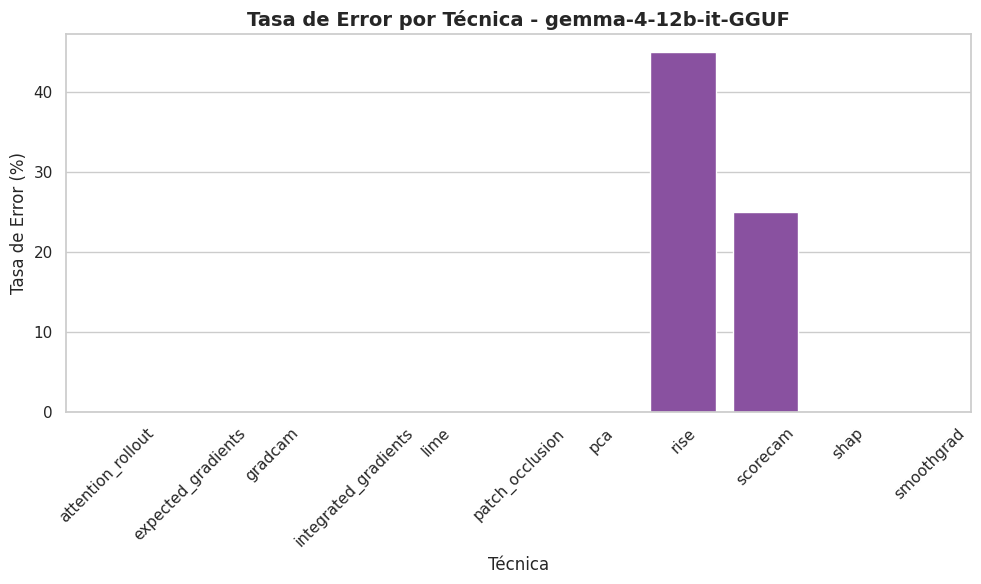

[INFO] Proceso finalizado correctamente.
[INFO] Iniciando procesamiento del modelo: Qwen3.5-9B-GGUF...
[INFO] Los resultados se guardarán en: Analisis_resultados_LLM/Qwen3.5-9B-GGUF
[OK] Guardado CSV completo: Analisis_resultados_LLM/Qwen3.5-9B-GGUF/Qwen3.5-9B-GGUF_Datos_Tabulares.csv
[OK] Guardado CSV de Métricas: Analisis_resultados_LLM/Qwen3.5-9B-GGUF/Qwen3.5-9B-GGUF_Metricas_Estadisticas.csv
[OK] Guardado CSV de Ranking de Fallos: Analisis_resultados_LLM/Qwen3.5-9B-GGUF/Qwen3.5-9B-GGUF_Ranking_Fallos_Imagenes.csv

RESUMEN GLOBAL DEL MODELO: Qwen3.5-9B-GGUF
 - Total de imágenes evaluadas: 220
 - Fallos totales (None):       103 (46.82%)
 - Puntuación Global:           Media 2.915 | Mediana 3.000
 - Tiempo Total Computacional:  147859.0 segundos (41h 4m)

----------------------------------------------------------------------
TOP 7: IMÁGENES CON MAYOR TASA DE ERROR
----------------------------------------------------------------------
 - 0c3902af-d173-4cf3-8572-c00c470d63ef.png: 7 fal

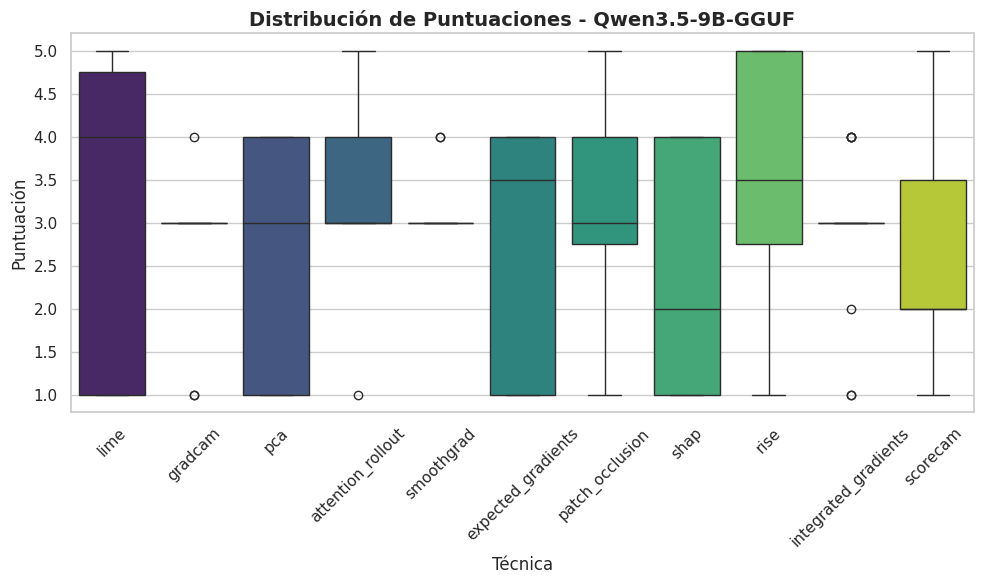

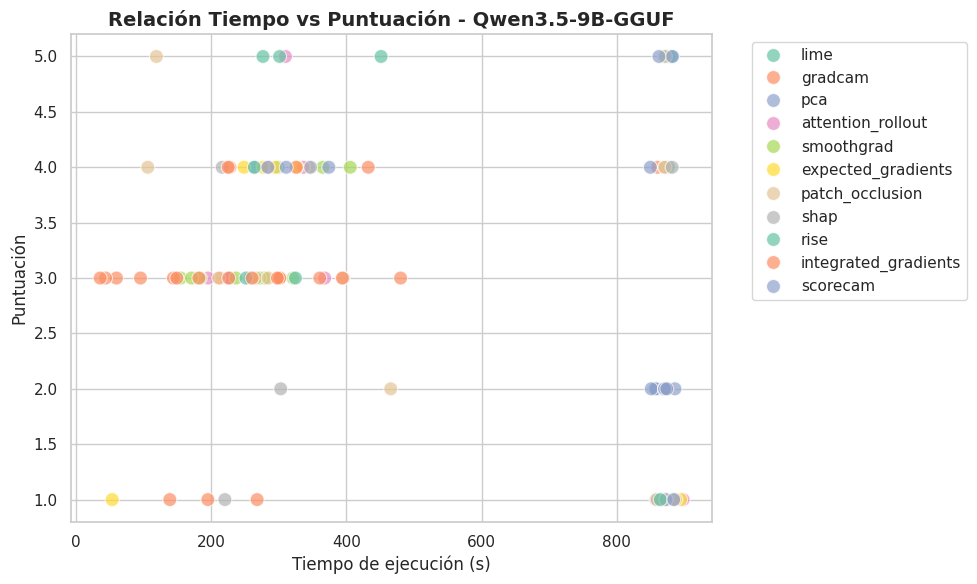

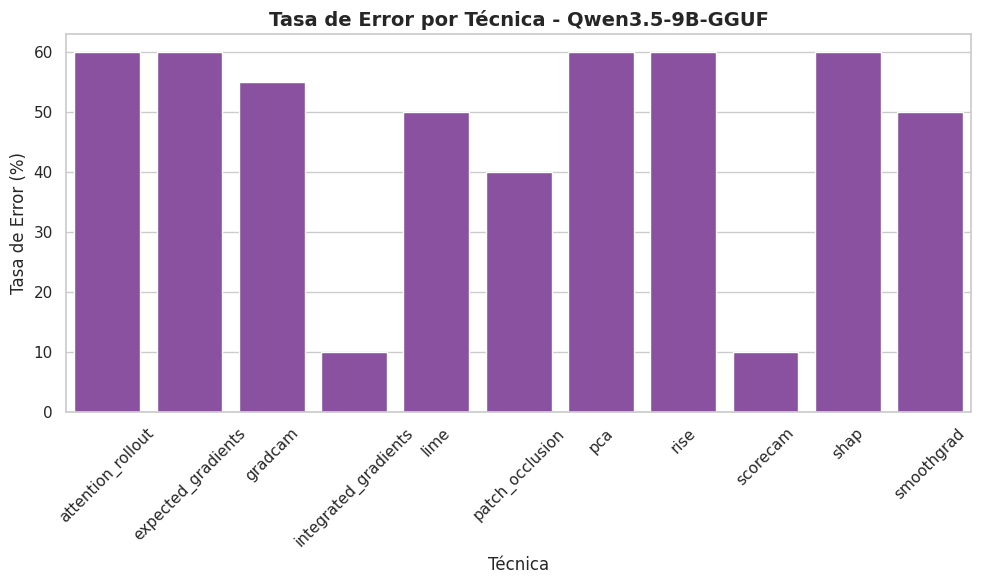

[INFO] Proceso finalizado correctamente.
[INFO] Iniciando procesamiento del modelo: gemma-4-26B-A4B-it-GGUF...
[INFO] Los resultados se guardarán en: Analisis_resultados_LLM/gemma-4-26B-A4B-it-GGUF
[OK] Guardado CSV completo: Analisis_resultados_LLM/gemma-4-26B-A4B-it-GGUF/gemma-4-26B-A4B-it-GGUF_Datos_Tabulares.csv
[OK] Guardado CSV de Métricas: Analisis_resultados_LLM/gemma-4-26B-A4B-it-GGUF/gemma-4-26B-A4B-it-GGUF_Metricas_Estadisticas.csv
[OK] Guardado CSV de Ranking de Fallos: Analisis_resultados_LLM/gemma-4-26B-A4B-it-GGUF/gemma-4-26B-A4B-it-GGUF_Ranking_Fallos_Imagenes.csv

RESUMEN GLOBAL DEL MODELO: gemma-4-26B-A4B-it-GGUF
 - Total de imágenes evaluadas: 220
 - Fallos totales (None):       23 (10.45%)
 - Puntuación Global:           Media 3.766 | Mediana 4.000
 - Tiempo Total Computacional:  11458.8 segundos (3h 10m)

----------------------------------------------------------------------
TOP 7: IMÁGENES CON MAYOR TASA DE ERROR
---------------------------------------------------

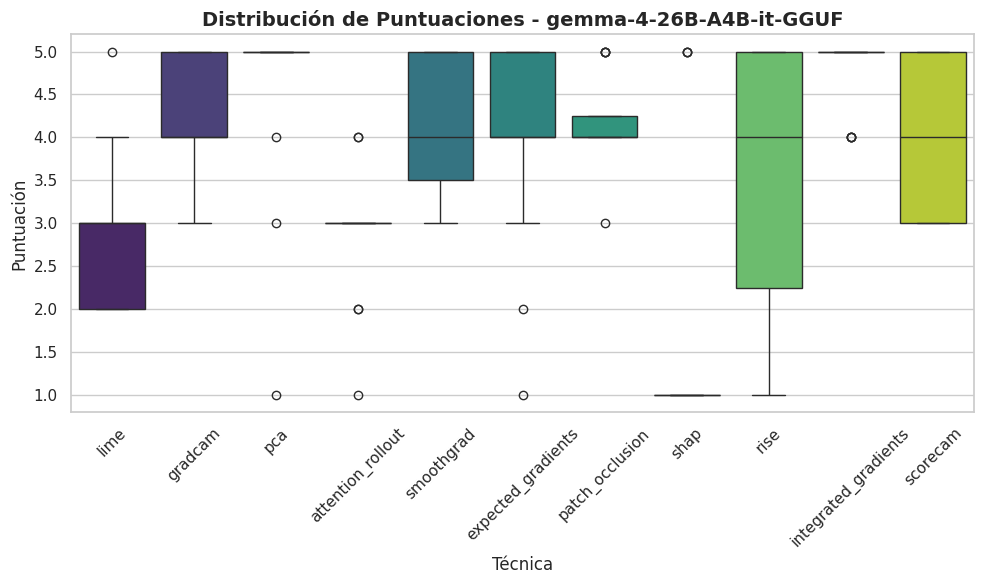

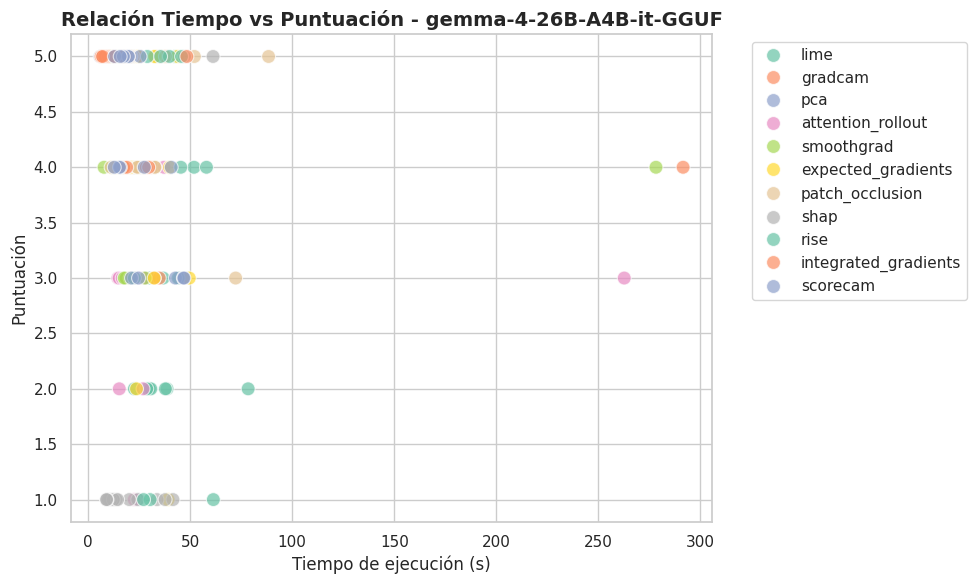

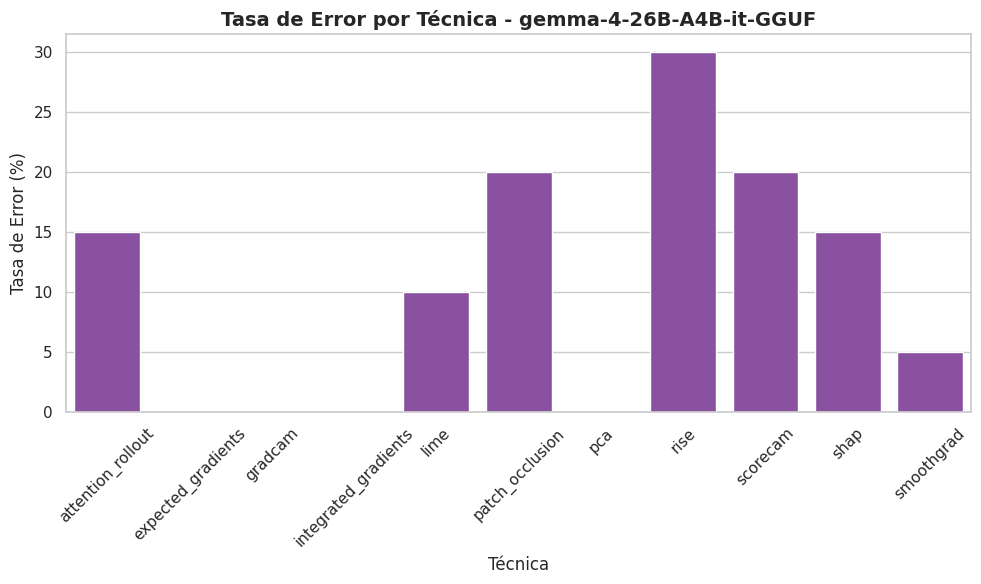

[INFO] Proceso finalizado correctamente.


In [13]:
modelos = ["Qwen3.5-27B-GGUF",
           "gemma-4-E2B-it-GGUF",
           "Qwen3.8-27B-GGUF",
           "Qwen3.5-2B-GGUF",
           "Qwen3.5-4B-GGUF",
           "gemma-4-E4B-it-GGUF",
           "gemma-4-12b-it-GGUF",
           "Qwen3.5-9B-GGUF",
           "gemma-4-26B-A4B-it-GGUF"]
for modelo in modelos:
  RUTA_DEL_MODELO = "LLM_dataset3_googleViT/"+ modelo
  procesar_modelo(RUTA_DEL_MODELO)

[INFO] Iniciando análisis global de modelos y técnicas...
[INFO] Los resultados globales se guardarán en: Analisis_resultados_LLM/Analisis_Global_Resultados

INFORME DE RENDIMIENTO ESTRUCTURAL GLOBAL
 - Modelos evaluados:     9 (Qwen3.5-27B-GGUF, gemma-4-E2B-it-GGUF, Qwen3.8-27B-GGUF, Qwen3.5-2B-GGUF, gemma-4-26B-A4B-it-GGUF, Qwen3.5-4B-GGUF, gemma-4-E4B-it-GGUF, gemma-4-12b-it-GGUF, Qwen3.5-9B-GGUF)
 - Técnicas totales:      11
 - Volumen total:         1980 evaluaciones procesadas.

-------------------------------------------------------------------------------------
RENDIMIENTO POR MODELO (ESTABILIDAD Y COSTE):
 * Qwen3.5-27B-GGUF          | Media: 2.351 | Fallos:   5.45% | Tiempo:     7h 29m
 * Qwen3.5-2B-GGUF           | Media: 3.305 | Fallos:  62.73% | Tiempo:    16h 22m
 * Qwen3.5-4B-GGUF           | Media: 3.340 | Fallos:   7.73% | Tiempo:    14h 36m
 * Qwen3.5-9B-GGUF           | Media: 2.915 | Fallos:  46.82% | Tiempo:     41h 4m
 * Qwen3.8-27B-GGUF          | Media: 2.150 | 

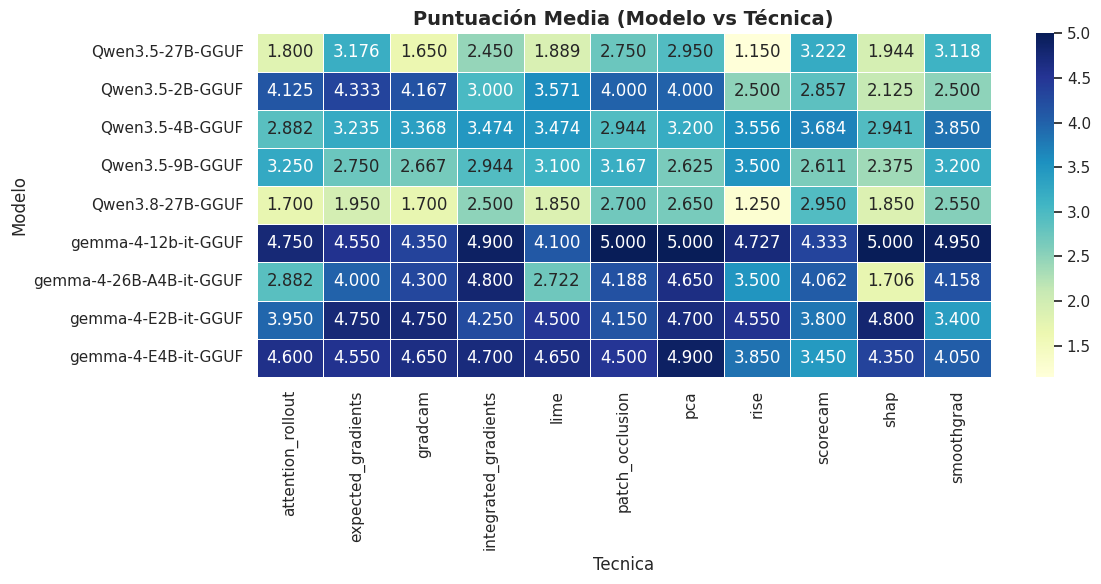

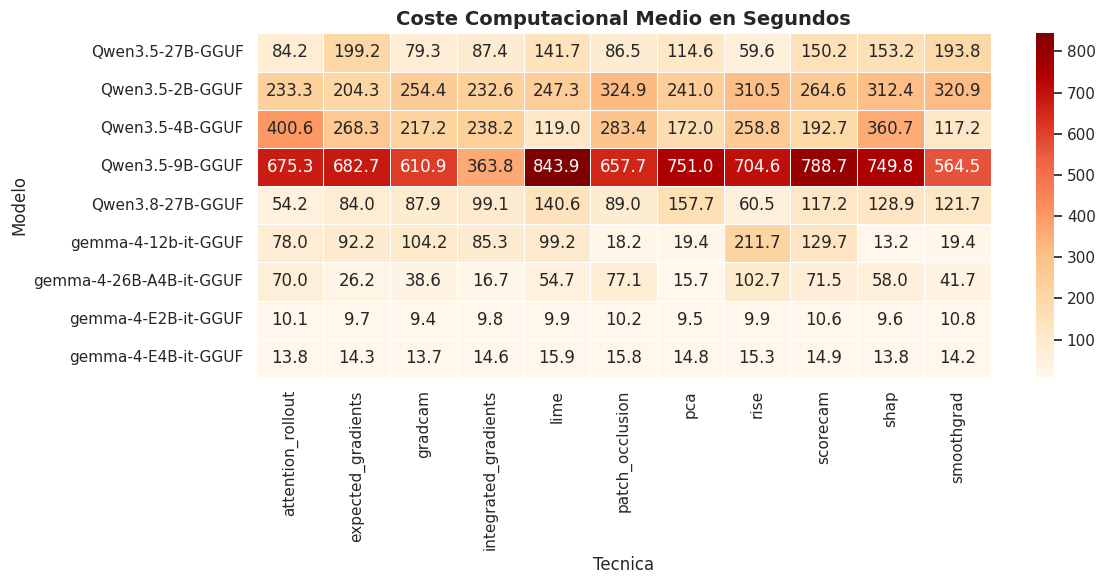

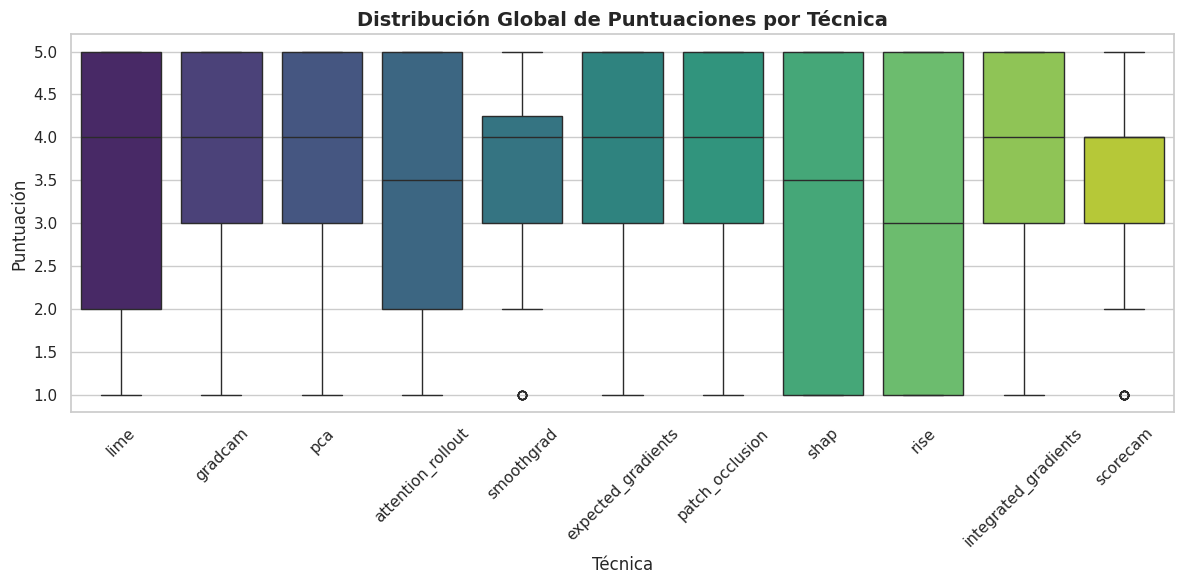

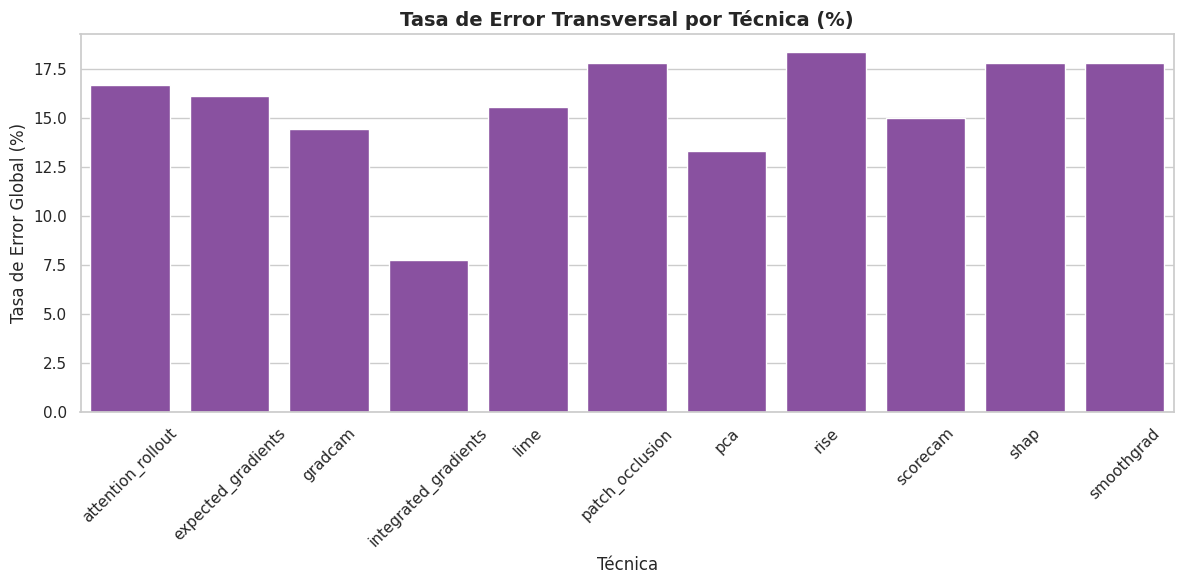

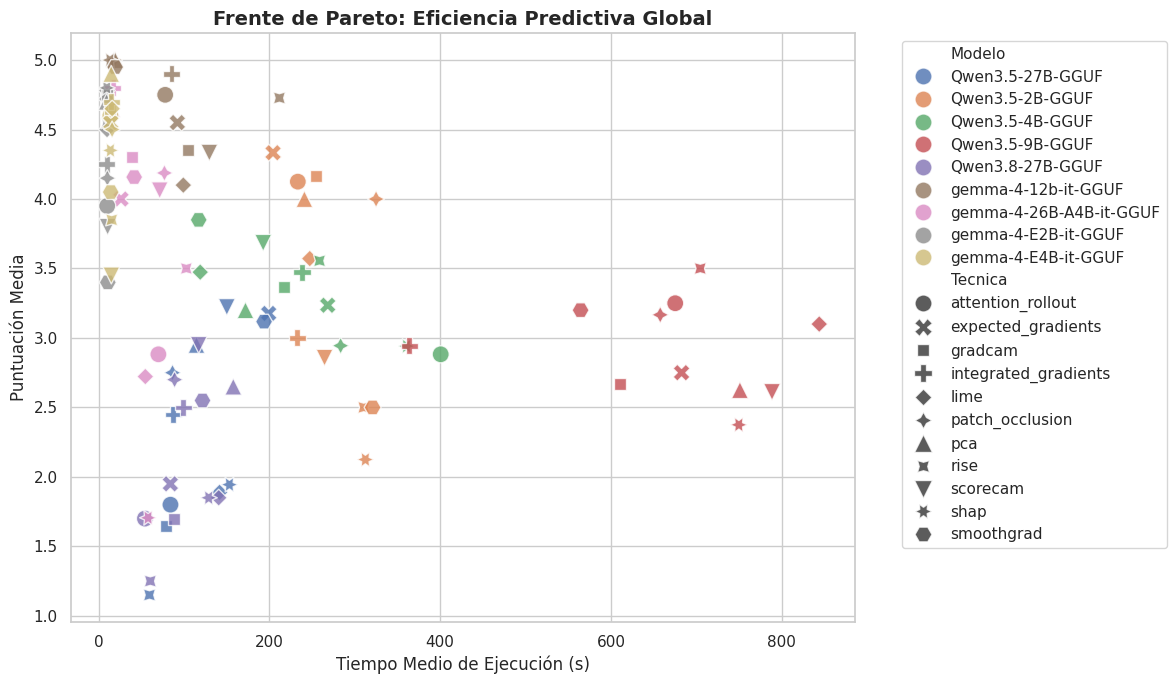

[INFO] Análisis global completado con éxito.


In [14]:
def analisis_global_modelos(ruta_raiz):
    print("[INFO] Iniciando análisis global de modelos y técnicas...")
    lista_dataframes = []

    if not os.path.exists(ruta_raiz):
        print(f"[ERROR] No se encuentra la ruta raíz: {ruta_raiz}")
        return

    # ==========================================
    # CREACIÓN DE DIRECTORIOS DE SALIDA
    # ==========================================
    carpeta_base_salida = "Analisis_resultados_LLM"
    ruta_salida = os.path.join(carpeta_base_salida, "Analisis_Global_Resultados")
    os.makedirs(ruta_salida, exist_ok=True)
    print(f"[INFO] Los resultados globales se guardarán en: {ruta_salida}")

    # ==========================================
    #  LECTURA Y CONSOLIDACIÓN DE DATOS
    # ==========================================
    for modelo in os.listdir(ruta_raiz):
        ruta_modelo = os.path.join(ruta_raiz, modelo)

        if os.path.isdir(ruta_modelo):
            for tecnica in os.listdir(ruta_modelo):
                ruta_tecnica = os.path.join(ruta_modelo, tecnica)

                if os.path.isdir(ruta_tecnica):
                    archivos_csv = [f for f in os.listdir(ruta_tecnica) if f.endswith('.csv')]
                    for archivo in archivos_csv:
                        ruta_csv = os.path.join(ruta_tecnica, archivo)
                        try:
                            df_parcial = pd.read_csv(ruta_csv)
                            df_parcial['Tecnica'] = tecnica
                            df_parcial['Modelo'] = modelo
                            lista_dataframes.append(df_parcial)
                        except Exception as e:
                            print(f"[AVISO] Error leyendo {ruta_csv}: {e}")

    if not lista_dataframes:
        print("[ERROR] No se encontraron datos CSV en la estructura.")
        return

    df_consolidado = pd.concat(lista_dataframes, ignore_index=True)
    df_consolidado['puntuacion'] = pd.to_numeric(df_consolidado['puntuacion'], errors='coerce')
    df_consolidado['tiempo_segundos'] = pd.to_numeric(df_consolidado['tiempo_segundos'], errors='coerce')

    ruta_tabular = os.path.join(ruta_salida, "Consolidado_Global_Datos.csv")
    df_consolidado.to_csv(ruta_tabular, index=False)

    # ==========================================
    # CÁLCULO DE MÉTRICAS CRUZADAS Y GLOBALES
    # ==========================================
    # Métricas por Modelo y Técnica
    df_metricas_cruzadas = df_consolidado.groupby(['Modelo', 'Tecnica']).agg(
        Total_Imagenes=('imagen', 'count'),
        Fallos_None=('puntuacion', lambda x: x.isna().sum()),
        Puntuacion_Media=('puntuacion', 'mean'),
        Puntuacion_Mediana=('puntuacion', 'median'),
        Tiempo_Total=('tiempo_segundos', 'sum'),
        Tiempo_Medio=('tiempo_segundos', 'mean')
    ).reset_index()
    df_metricas_cruzadas['Porcentaje_Fallos'] = (df_metricas_cruzadas['Fallos_None'] / df_metricas_cruzadas['Total_Imagenes']) * 100
    df_metricas_cruzadas.to_csv(os.path.join(ruta_salida, "Metricas_Cruzadas_Modelo_Tecnica.csv"), index=False)

    # Métricas Agregadas por Modelo
    df_metricas_modelos = df_consolidado.groupby('Modelo').agg(
        Total_Imagenes=('imagen', 'count'),
        Fallos_None=('puntuacion', lambda x: x.isna().sum()),
        Puntuacion_Media_Global=('puntuacion', 'mean'),
        Tiempo_Total_Global=('tiempo_segundos', 'sum')
    ).reset_index()
    df_metricas_modelos['Porcentaje_Fallos_Global'] = (df_metricas_modelos['Fallos_None'] / df_metricas_modelos['Total_Imagenes']) * 100
    df_metricas_modelos.to_csv(os.path.join(ruta_salida, "Rendimiento_Global_Por_Modelo.csv"), index=False)

    # Métricas Agregadas por Técnica (Transversal)
    df_metricas_tecnicas = df_consolidado.groupby('Tecnica').agg(
        Total_Imagenes=('imagen', 'count'),
        Fallos_None=('puntuacion', lambda x: x.isna().sum()),
        Puntuacion_Media_Global=('puntuacion', 'mean'),
        Puntuacion_Mediana_Global=('puntuacion', 'median'),
        Tiempo_Medio_Global=('tiempo_segundos', 'mean')
    ).reset_index()
    df_metricas_tecnicas['Porcentaje_Fallos_Global'] = (df_metricas_tecnicas['Fallos_None'] / df_metricas_tecnicas['Total_Imagenes']) * 100
    df_metricas_tecnicas.to_csv(os.path.join(ruta_salida, "Rendimiento_Global_Por_Tecnica.csv"), index=False)

    # ==========================================
    #  RANKING GLOBAL DE IMÁGENES COMPLEJAS
    # ==========================================
    df_fallos = df_consolidado[df_consolidado['puntuacion'].isna()]
    df_ranking_global = pd.DataFrame()

    if not df_fallos.empty:
        df_ranking_global = df_fallos.groupby('imagen').size().reset_index(name='Cantidad_Fallos_Globales')
        df_ranking_global = df_ranking_global.sort_values(by='Cantidad_Fallos_Globales', ascending=False)
        df_ranking_global.to_csv(os.path.join(ruta_salida, "Ranking_Global_Imagenes_Complejas.csv"), index=False)

    # ==========================================
    #  IMPRESIÓN DEL RESUMEN GLOBAL ALINEADO
    # ==========================================
    print("\n" + "=" * 85)
    print("INFORME DE RENDIMIENTO ESTRUCTURAL GLOBAL")
    print("=" * 85)
    print(f" - {'Modelos evaluados:':<22} {df_consolidado['Modelo'].nunique()} ({', '.join(df_consolidado['Modelo'].unique())})")
    print(f" - {'Técnicas totales:':<22} {df_consolidado['Tecnica'].nunique()}")
    print(f" - {'Volumen total:':<22} {len(df_consolidado)} evaluaciones procesadas.")

    print("\n" + "-" * 85)
    print("RENDIMIENTO POR MODELO (ESTABILIDAD Y COSTE):")
    for index, row in df_metricas_modelos.iterrows():
        horas = int(row['Tiempo_Total_Global'] // 3600)
        minutos = int((row['Tiempo_Total_Global'] % 3600) // 60)
        tiempo_str = f"{horas}h {minutos}m" if horas > 0 else f"{row['Tiempo_Total_Global']:.1f}s"
        print(f" * {row['Modelo']:<25} | Media: {row['Puntuacion_Media_Global']:>5.3f} | Fallos: {row['Porcentaje_Fallos_Global']:>6.2f}% | Tiempo: {tiempo_str:>10}")

    print("\n" + "-" * 85)
    print("RENDIMIENTO POR TÉCNICA (TRANSVERSAL):")
    for index, row in df_metricas_tecnicas.iterrows():
        print(f" * {row['Tecnica']:<25} | Media: {row['Puntuacion_Media_Global']:>5.3f} | Fallos: {row['Porcentaje_Fallos_Global']:>6.2f}% | Tiempo Medio: {row['Tiempo_Medio_Global']:>8.2f}s")

    print("\n" + "-" * 85)
    print("TOP 10 IMÁGENES MÁS DESAFIANTES (FALLO MULTI-MODELO):")
    if not df_ranking_global.empty:
        for i, row in df_ranking_global.head(10).iterrows():
            print(f" - {row['imagen']:<25} | Falló {row['Cantidad_Fallos_Globales']:>3} veces en total.")
    else:
        print(" - Ausencia total de fallos de evaluación.")
    print("=" * 85 + "\n")

    # ==========================================
    # VISUALIZACIONES GLOBALES
    # ==========================================
    print("[INFO] Generando visualizaciones cruzadas...")
    sns.set_theme(style="whitegrid")

    # Mapa de Calor: Modelo vs Técnica (Puntuación)
    pivot_puntuacion = df_metricas_cruzadas.pivot(index="Modelo", columns="Tecnica", values="Puntuacion_Media")
    plt.figure(figsize=(12, 6))
    sns.heatmap(pivot_puntuacion, annot=True, cmap="YlGnBu", fmt=".3f", linewidths=.5)
    plt.title("Puntuación Media (Modelo vs Técnica)", fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.savefig(os.path.join(ruta_salida, "Global_Heatmap_Puntuaciones.png"))
    plt.show()

    # Mapa de Calor: Modelo vs Técnica (Tiempo)
    pivot_tiempo = df_metricas_cruzadas.pivot(index="Modelo", columns="Tecnica", values="Tiempo_Medio")
    plt.figure(figsize=(12, 6))
    sns.heatmap(pivot_tiempo, annot=True, cmap="OrRd", fmt=".1f", linewidths=.5)
    plt.title("Coste Computacional Medio en Segundos", fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.savefig(os.path.join(ruta_salida, "Global_Heatmap_Tiempos.png"))
    plt.show()

    # Boxplot Global por Técnica
    plt.figure(figsize=(12, 6))
    sns.boxplot(data=df_consolidado, x='Tecnica', y='puntuacion', hue='Tecnica', palette='viridis', legend=False)
    plt.title("Distribución Global de Puntuaciones por Técnica", fontsize=14, fontweight='bold')
    plt.ylabel("Puntuación")
    plt.xlabel("Técnica")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.savefig(os.path.join(ruta_salida, "Global_Boxplot_Tecnicas.png"))
    plt.show()

    # Tasa de Error Global por Técnica
    plt.figure(figsize=(12, 6))
    sns.barplot(data=df_metricas_tecnicas, x='Tecnica', y='Porcentaje_Fallos_Global', color='#8e44ad')
    plt.title("Tasa de Error Transversal por Técnica (%)", fontsize=14, fontweight='bold')
    plt.ylabel("Tasa de Error Global (%)")
    plt.xlabel("Técnica")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.savefig(os.path.join(ruta_salida, "Global_Tasa_Errores_Tecnicas.png"))
    plt.show()

    # Frente de Pareto: Eficiencia
    plt.figure(figsize=(12, 7))
    sns.scatterplot(data=df_metricas_cruzadas, x='Tiempo_Medio', y='Puntuacion_Media',
                    hue='Modelo', style='Tecnica', s=150, alpha=0.8, palette="deep")
    plt.title("Frente de Pareto: Eficiencia Predictiva Global", fontsize=14, fontweight='bold')
    plt.ylabel("Puntuación Media")
    plt.xlabel("Tiempo Medio de Ejecución (s)")
    plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
    plt.tight_layout()
    plt.savefig(os.path.join(ruta_salida, "Global_Pareto_Eficiencia.png"))
    plt.show()

    print("[INFO] Análisis global completado con éxito.")

# ==========================================
# EJECUCIÓN
# ==========================================
RUTA_RAIZ_MODELOS = "LLM_dataset3_googleViT/"
analisis_global_modelos(RUTA_RAIZ_MODELOS)

In [18]:
carpeta_origen = "Analisis_resultados_LLM"
carpeta_destino = "Analisis_resultados_LLM_dataset3_googleViT"

carpeta = Path(carpeta_origen)
lista_tuplas = []

# rglob('*') busca recursivamente todos los elementos
for ruta_archivo in carpeta.rglob('*'):
    if ruta_archivo.is_file():
        # Ruta local
        ruta_local_str = str(ruta_archivo)

        # Le quitamos la carpeta base original para quedarnos con el resto de la ruta
        ruta_relativa = ruta_archivo.relative_to(carpeta)

        # Añadimos la nueva carpeta base para el bucket
        ruta_bucket = Path(carpeta_destino) / ruta_relativa

        # as_posix() asegura que la ruta use '/' (requerido por los buckets de HF)
        ruta_bucket_str = ruta_bucket.as_posix()

        # Añadimos la tupla (ruta_local, ruta_destino_bucket)
        lista_tuplas.append((ruta_local_str, ruta_bucket_str))

if lista_tuplas:
    print(lista_tuplas[0], len(lista_tuplas))

# Subimos al bucket
api.batch_bucket_files(
    bucket_id,
    add=lista_tuplas,
)

('Analisis_resultados_LLM/Qwen3.5-27B-GGUF/Qwen3.5-27B-GGUF_Dispersion.png', 'Analisis_resultados_LLM_dataset3_googleViT/Qwen3.5-27B-GGUF/Qwen3.5-27B-GGUF_Dispersion.png') 61


Processing Files (0 / 0)      : |          |  0.00B /  0.00B            

New Data Upload               : |          |  0.00B /  0.00B            

  ...nking_Fallos_Imagenes.csv: 100%|#########9|   366B /   367B            

  ...4-E2B-it-GGUF_Boxplot.png: 100%|#########9| 59.3kB / 59.3kB            

  ...uzadas_Modelo_Tecnica.csv: 100%|#########9| 8.91kB / 8.91kB            

... (3 outputs left out)

  ...-GGUF_Datos_Tabulares.csv: 100%|#########9| 20.1kB / 20.1kB            

  ...Metricas_Estadisticas.csv: 100%|#########9| 2.10kB / 2.10kB            

  ...Metricas_Estadisticas.csv: 100%|#########9| 2.13kB / 2.14kB            

  ...Metricas_Estadisticas.csv: 100%|#########9| 2.01kB / 2.01kB            

In [15]:
# carpeta = Path("Analisis_resultados_LLM")
# lista_tuplas = []

# # rglob('*') busca recursivamente todos los elementos dentro de la carpeta y subcarpetas
# for ruta_archivo in carpeta.rglob('*'):
#     # Nos aseguramos de que es un archivo y no una carpeta
#     if ruta_archivo.is_file():
#         ruta_str = str(ruta_archivo)
#         # Añadimos la tupla con la ruta repetida (ruta_local, ruta_destino)
#         lista_tuplas.append((ruta_str, ruta_str))

# print (lista_tuplas[0], len(lista_tuplas))

# api.batch_bucket_files(
#     bucket_id,
#     add=lista_tuplas,
# )